# Comprehensive Guide to Computational Neuroscience with Python
*(Optimized for Google Colab)*

Welcome to this interactive guide on Computational Neuroscience! This notebook is designed to run in Google Colab, making it easy to execute Python code without any local setup.

## Table of Contents
1. Introduction
2. Setting Up the Environment
3. Basic Tools: NumPy & Matplotlib
4. Single Neuron Models
   - Leaky Integrate-and-Fire (LIF) Model
   - Hodgkin-Huxley Model
5. Neural Networks
   - Simulating a simple network
6. Data Analysis in Neuroscience
7. Conclusion & Next Steps


## 1. Introduction
Computational neuroscience uses mathematical models, theoretical analysis, and abstractions of the brain to understand the principles that govern the development, structure, physiology, and cognitive abilities of the nervous system. Python is the dominant language in this field due to its rich ecosystem of scientific libraries.


## 2. Setting Up the Environment
In Google Colab, most of the libraries we need (like `numpy`, `scipy`, and `matplotlib`) are already installed. Let's import them. We also install `brian2` later for more complex simulations.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Ensure plots are displayed inline in Colab
%matplotlib inline


## 3. Basic Tools: NumPy & Matplotlib
Before simulating neurons, let's look at how we handle data and plot it. Neuronal signals are often represented as time series.


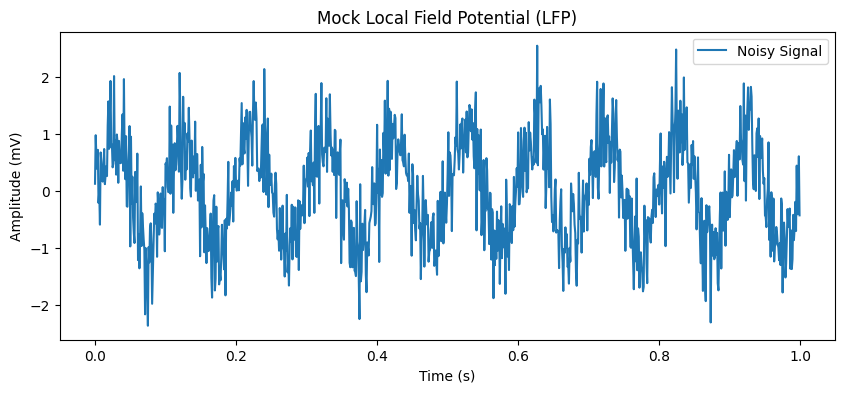

In [2]:
# Create a time vector
t = np.arange(0, 1.0, 0.001) # 1 second, 1 ms step

# Create a mock EEG or local field potential (LFP) signal using a sine wave + noise
freq = 10 # 10 Hz (Alpha band)
signal = np.sin(2 * np.pi * freq * t) + np.random.normal(0, 0.5, len(t))

plt.figure(figsize=(10, 4))
plt.plot(t, signal, label='Noisy Signal')
plt.title('Mock Local Field Potential (LFP)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (mV)')
plt.legend()
plt.show()


## 4. Single Neuron Models

### Leaky Integrate-and-Fire (LIF) Model
The LIF model is one of the simplest spiking neuron models. It models the neuron as an RC circuit. When the membrane potential reaches a certain threshold, the neuron 'fires' a spike and resets.


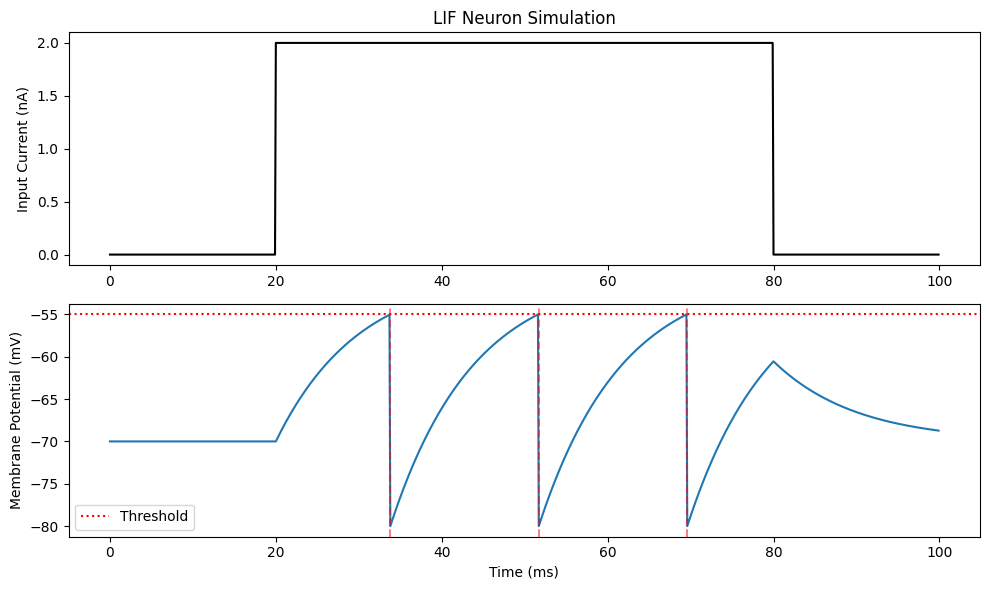

In [3]:
# LIF parameters
tau_m = 10.0      # Membrane time constant (ms)
V_rest = -70.0    # Resting potential (mV)
V_reset = -80.0   # Reset potential (mV)
V_thresh = -55.0  # Firing threshold (mV)
R = 10.0          # Membrane resistance (MOhm)

# Simulation parameters
dt = 0.1          # Time step (ms)
t = np.arange(0, 100, dt) # Simulate 100 ms

# Applied current (Input)
I = np.zeros_like(t)
I[200:800] = 2.0  # Apply a 2.0 nA pulse between 20ms and 80ms

# State variables
V = np.zeros_like(t)
V[0] = V_rest
spikes = []

# Euler integration
for i in range(1, len(t)):
    # Calculate derivative
    dV = (-(V[i-1] - V_rest) + R * I[i-1]) / tau_m
    # Update membrane potential
    V[i] = V[i-1] + dV * dt
    
    # Check for spike
    if V[i] >= V_thresh:
        V[i] = V_reset
        spikes.append(t[i])

# Plotting
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.plot(t, I, 'k')
plt.ylabel('Input Current (nA)')
plt.title('LIF Neuron Simulation')

plt.subplot(2, 1, 2)
plt.plot(t, V)
for spike in spikes:
    plt.axvline(x=spike, color='r', linestyle='--', alpha=0.5)
plt.ylabel('Membrane Potential (mV)')
plt.xlabel('Time (ms)')
plt.axhline(V_thresh, color='r', linestyle=':', label='Threshold')
plt.legend()
plt.tight_layout()
plt.show()


### Hodgkin-Huxley Model
The Hodgkin-Huxley model is a more biologically realistic model that explicitly models ion channels (Sodium and Potassium). It's described by a set of non-linear differential equations.


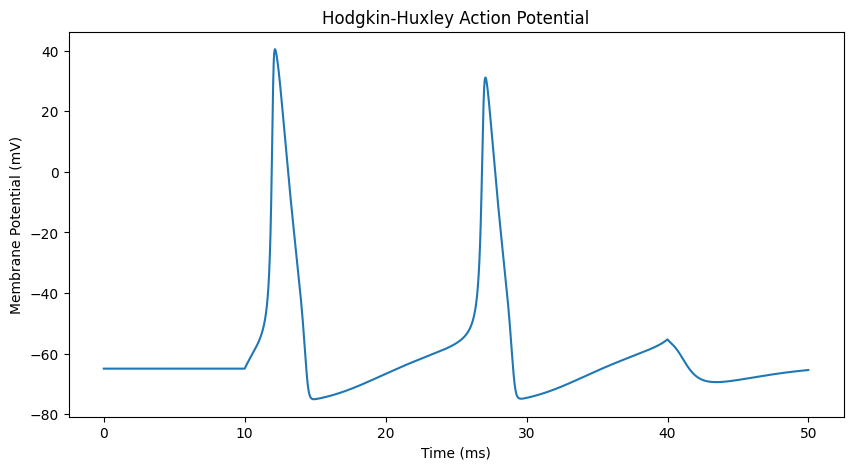

In [4]:
# Simplified Hodgkin-Huxley using Euler method
C_m  =   1.0 # uF/cm^2
g_Na = 120.0 # mS/cm^2
g_K  =  36.0 # mS/cm^2
g_L  =   0.3 # mS/cm^2
E_Na =  50.0 # mV
E_K  = -77.0 # mV
E_L  = -54.387 # mV

t = np.arange(0, 50, 0.01)

def alpha_m(V): return 0.1*(V+40.0)/(1.0 - np.exp(-(V+40.0) / 10.0))
def beta_m(V):  return 4.0*np.exp(-(V+65.0) / 18.0)
def alpha_h(V): return 0.07*np.exp(-(V+65.0) / 20.0)
def beta_h(V):  return 1.0/(1.0 + np.exp(-(V+35.0) / 10.0))
def alpha_n(V): return 0.01*(V+55.0)/(1.0 - np.exp(-(V+55.0) / 10.0))
def beta_n(V):  return 0.125*np.exp(-(V+65) / 80.0)

I = np.zeros_like(t)
I[1000:4000] = 10.0 # 10 uA/cm^2 pulse

V = np.zeros_like(t)
m = np.zeros_like(t)
h = np.zeros_like(t)
n = np.zeros_like(t)

V[0] = -65.0
m[0] = alpha_m(V[0]) / (alpha_m(V[0]) + beta_m(V[0]))
h[0] = alpha_h(V[0]) / (alpha_h(V[0]) + beta_h(V[0]))
n[0] = alpha_n(V[0]) / (alpha_n(V[0]) + beta_n(V[0]))

for i in range(1, len(t)):
    dt = 0.01
    # Ionic currents
    I_Na = g_Na * m[i-1]**3 * h[i-1] * (V[i-1] - E_Na)
    I_K = g_K  * n[i-1]**4 * (V[i-1] - E_K)
    I_L = g_L  * (V[i-1] - E_L)
    
    dV = (I[i-1] - (I_Na + I_K + I_L)) / C_m
    V[i] = V[i-1] + dV * dt
    
    m[i] = m[i-1] + (alpha_m(V[i-1])*(1-m[i-1]) - beta_m(V[i-1])*m[i-1]) * dt
    h[i] = h[i-1] + (alpha_h(V[i-1])*(1-h[i-1]) - beta_h(V[i-1])*h[i-1]) * dt
    n[i] = n[i-1] + (alpha_n(V[i-1])*(1-n[i-1]) - beta_n(V[i-1])*n[i-1]) * dt

plt.figure(figsize=(10, 5))
plt.plot(t, V)
plt.title('Hodgkin-Huxley Action Potential')
plt.ylabel('Membrane Potential (mV)')
plt.xlabel('Time (ms)')
plt.show()


## 5. Neural Networks
Simulating networks of neurons from scratch can be computationally intensive and mathematically complex. We can use specialized libraries like `brian2` for this.

Let's install it first (this is perfect for Colab):


In [5]:
!pip install brian2


Now let's simulate a simple network of excitatory and inhibitory LIF neurons using Brian2.


WARNING    'i' is an internal variable of group 'synapses', but also exists in the run namespace with the value 4999. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'i' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value 4999. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


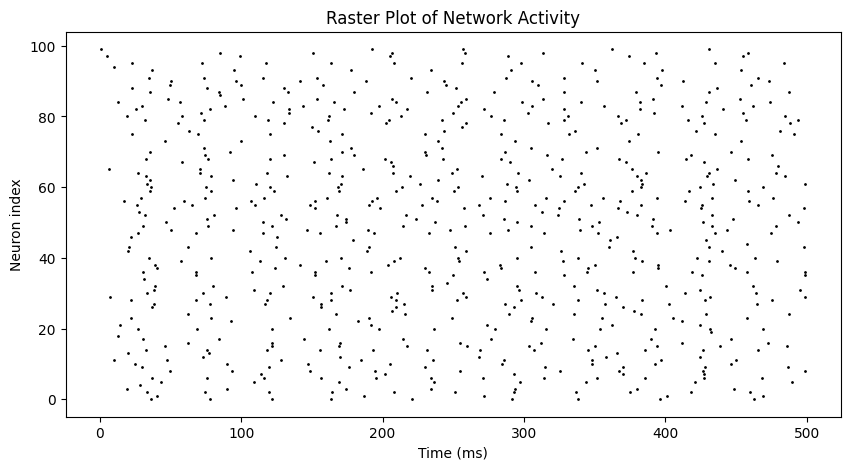

In [6]:
from brian2 import *

start_scope()

# Network parameters
N_E = 80
N_I = 20
taum = 20*ms
taue = 5*ms
taui = 10*ms
Vt = -50*mV
Vr = -60*mV
El = -49*mV

# Neuron equations
eqs = '''
dv/dt  = (ge+gi-(v-El))/taum : volt (unless refractory)
dge/dt = -ge/taue : volt
dgi/dt = -gi/taui : volt
'''

P = NeuronGroup(N_E+N_I, eqs, threshold='v>Vt', reset='v=Vr', refractory=5*ms, method='exact')
P.v = 'Vr + rand() * (Vt - Vr)'
P.ge = 0*mV
P.gi = 0*mV

we = (60*0.27/10)*mV # excitatory synaptic weight
wi = (-20*4.5/10)*mV # inhibitory synaptic weight

Ce = Synapses(P, P, on_pre='ge += we')
Ci = Synapses(P, P, on_pre='gi += wi')
Ce.connect('i<N_E', p=0.1)
Ci.connect('i>=N_E', p=0.1)

# Monitor spikes
M = SpikeMonitor(P)

run(500*ms)

plt.figure(figsize=(10, 5))
plt.plot(M.t/ms, M.i, '.k', markersize=2)
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Raster Plot of Network Activity')
plt.show()


## 6. Data Analysis in Neuroscience
Often, computational neuroscientists analyze real data. Let's look at how to compute a Peristimulus Time Histogram (PSTH), which shows the firing rate of a neuron around a stimulus.


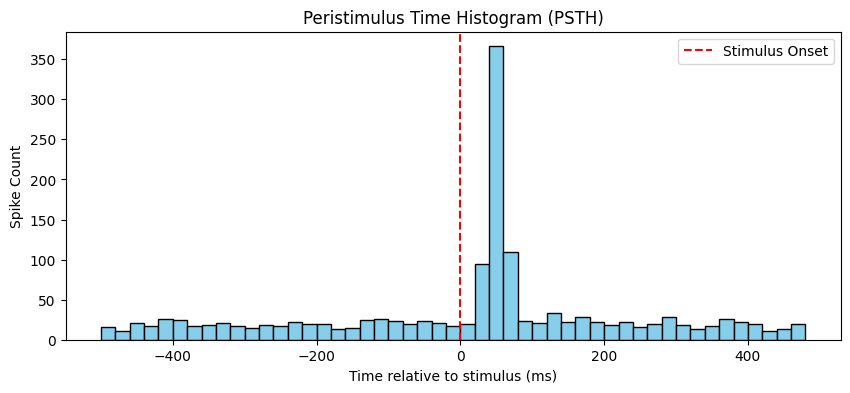

In [7]:
# Simulate spike times around a stimulus at t=0
# Assume stimulus is repeated 50 times
n_trials = 50
spike_times = []

for _ in range(n_trials):
    # Background firing (random)
    bg = np.random.uniform(-500, 500, 20)
    # Evoked response (gaussian around 50ms)
    evoked = np.random.normal(50, 10, 10)
    spike_times.extend(bg)
    spike_times.extend(evoked)

plt.figure(figsize=(10, 4))
plt.hist(spike_times, bins=np.arange(-500, 500, 20), color='skyblue', edgecolor='black')
plt.axvline(0, color='r', linestyle='--', label='Stimulus Onset')
plt.title('Peristimulus Time Histogram (PSTH)')
plt.xlabel('Time relative to stimulus (ms)')
plt.ylabel('Spike Count')
plt.legend()
plt.show()


## 7. Conclusion & Next Steps
We've covered:
- Using Python libraries (NumPy, Matplotlib) for signals.
- Simulating single neurons (LIF, Hodgkin-Huxley).
- Simulating networks using Brian2.
- Basic spike data analysis (PSTH).

**Next Steps:**
- Explore more complex network dynamics (e.g., synchronous firing, oscillations).
- Look into learning rules like Spike-Time Dependent Plasticity (STDP).
- Try analyzing open datasets (e.g., from the Allen Institute).
- Libraries to explore further: `Brian2`, `NEURON`, `NEST`, `MNE-Python` (for EEG/MEG).
